<a href="https://colab.research.google.com/github/SethSekyere/ML-engineering-portfolio/blob/main/projects/03-PixelForge/PixelForge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PixelForge
### Image Color Quantization Using K-Means Clustering

PixelForge is an unsupervised machine learning project that explores the application of **K-Means clustering to image color quantization**.

The project implements the K-Means algorithm from scratch and applies it to RGB pixel data to reduce the number of distinct colors used to represent a digital image.

By grouping similar pixel colors into clusters and replacing individual pixel values with their corresponding cluster centroids, PixelForge demonstrates how unsupervised learning can simplify image representations while retaining their essential visual characteristics.

The project combines fundamental clustering techniques with practical image processing to demonstrate a real-world application of machine learning.

## Project Objectives

- Implement the K-Means clustering algorithm from scratch using Python and NumPy.
- Understand how centroid initialization, cluster assignment, and centroid updates work together.
- Apply K-Means to a sample dataset to explore clustering behavior.
- Extend the clustering implementation to RGB image data.
- Perform image color quantization by reducing the number of distinct colors in an image.
- Visualize clustering results and investigate the relationship between palette size and image quality.

## Project Workflow

The project is organized into two major stages:

**1. K-Means Algorithm Development**

Develop and examine the core components of K-Means clustering, including distance calculations, nearest-centroid assignment, centroid updates, and iterative optimization.

**2. Image Color Quantization**

Apply the implemented algorithm to image pixel data, group similar RGB colors into clusters, and reconstruct the image using a reduced color palette.



## Expected Outcome

By the end of this project, the K-Means implementation will be applied to an image to generate a reduced-color representation using a predefined number of clusters.

The resulting visualizations will demonstrate how clustering can reduce color complexity and how different cluster counts influence the reconstructed image.

In [134]:
# ============================================================
# 1. Project Environment Setup
# ============================================================

from pathlib import Path
import sys

# Repository containing the ML Engineering portfolio.
REPO_URL = "https://github.com/SethSekyere/ML-engineering-portfolio.git"
REPO_DIR = Path("/content/ML-engineering-portfolio")

# Retrieve the latest project files from GitHub.
if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    print("Updating local repository...")
    !git -C {REPO_DIR} pull

# Define the PixelForge project directory.
PROJECT_DIR = REPO_DIR / "projects" / "03-PixelForge"
REQUIREMENTS_FILE = PROJECT_DIR / "requirements.txt"
UTILS_FILE = PROJECT_DIR / "utils.py"

# Validate the project structure.
assert PROJECT_DIR.exists(), (
    f"PixelForge project directory not found: {PROJECT_DIR}"
)
assert UTILS_FILE.exists(), (
    f"Project utility module not found: {UTILS_FILE}"
)
assert REQUIREMENTS_FILE.exists(), (
    f"Dependency file not found: {REQUIREMENTS_FILE}"
)

# Install project dependencies.
!pip install -r {REQUIREMENTS_FILE}

# Register the project directory for local Python imports.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

print("\nPixelForge environment initialized successfully.")
print(f"Repository: {REPO_DIR}")
print(f"Project directory: {PROJECT_DIR}")
print("Project structure verified.")
print("Dependencies installed.")

Updating local repository...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 5 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 644.11 KiB | 4.54 MiB/s, done.
From https://github.com/SethSekyere/ML-engineering-portfolio
   ba578bb..bdb5bce  main       -> origin/main
Updating ba578bb..bdb5bce
Fast-forward
 projects/03-PixelForge/PixelForge.ipynb | 98 ++++++++++++++++++---------------
 1 file changed, 55 insertions(+), 43 deletions(-)

PixelForge environment initialized successfully.
Repository: /content/ML-engineering-portfolio
Project directory: /content/ML-engineering-portfolio/projects/03-PixelForge
Project structure verified.
Dependencies installed.


In [135]:
# ============================================================
# 2. Utility Module Initialization
# ============================================================

import importlib
import matplotlib.pyplot as plt
import utils

# Reload the utility module to apply the latest code changes.
importlib.reload(utils)

# Import the functions required for the project.
from utils import *

# Enable inline visualization in the notebook.
%matplotlib inline

**K-Means Clustering: Algorithm Overview**

K-Means is an unsupervised machine learning algorithm that partitions a dataset into **K clusters** based on the similarity of its data points.

The objective is to group similar observations together by identifying representative points called *centroids*. Each centroid represents the center of its assigned cluster.

### How the Algorithm Works

K-Means follows an iterative process consisting of two main operations:

1. **Cluster Assignment:** Assign each data point to the nearest centroid based on a distance metric, typically Euclidean distance.
2. **Centroid Update:** Recalculate each centroid as the mean of all data points assigned to its cluster.

These operations repeat until the centroids stabilize or a predefined number of iterations is reached.

### Algorithm Workflow

The general K-Means procedure can be expressed as follows:

```python
# Initialize K cluster centroids.
centroids = kMeans_init_centroids(X, K)

# Iteratively refine cluster assignments and centroids.
for iteration in range(iterations):

    # Assign each data point to its nearest centroid.
    idx = find_closest_centroids(X, centroids)

    # Update centroids using the mean of assigned data points.
    centroids = compute_centroids(X, idx, K)
```

Here:

- `X` represents the input dataset.
- `K` specifies the desired number of clusters.
- `centroids` contains the current cluster centers.
- `idx` stores the cluster assignment for each data point.
- `iterations` determines the maximum number of refinement steps.

### Convergence and Initialization

K-Means generally converges to a stable clustering configuration. However, the final result can depend on the initial centroid positions.

Different initializations can produce different clustering results, including solutions that converge to local minima rather than the globally optimal clustering.

To improve the likelihood of obtaining a good solution, K-Means is often executed multiple times with different initial centroid positions. The resulting solutions can then be compared using the clustering cost function, also known as *distortion*.

### Application in PixelForge

In this project, K-Means is applied to image color quantization.

Each image pixel is represented as a three-dimensional data point containing its Red, Green, and Blue (RGB) values:

\[
x^{(i)} = [R^{(i)}, G^{(i)}, B^{(i)}]
\]

The algorithm groups pixels with similar colors into K clusters. The resulting centroids represent the reduced color palette used to reconstruct the image.

The following sections develop the two core operations of K-Means: nearest-centroid assignment and centroid recomputation.

**Nearest-Centroid Assignment**

The first step in K-Means clustering is to assign each data point to its nearest centroid.

Given a dataset \(X\) and a set of \(K\) centroids, the algorithm calculates the distance between every data point and every centroid. Each data point is then assigned to the centroid with the smallest distance.

For a data point $x^{(i)}$, its cluster assignment is determined by:

$$
c^{(i)} = \arg\min_{j \in \{0,1,\ldots,K-1\}}
\|x^{(i)} - \mu_j\|^2
$$

Where:

- $x^{(i)}$ represents the $i$-th data point.
- $\mu_j$ represents the $j$-th centroid.
- $K$ is the total number of clusters.
- $c^{(i)}$ is the index of the nearest centroid.

The result is stored in a one-dimensional array called `idx`, where each element represents the cluster assignment of its corresponding data point.

**Implementation considerations**

This implementation uses NumPy's broadcasting to calculate distances between all data points and centroids simultaneously, avoiding unnecessary Python loops.

Because the square root operation does not change which distance is smallest, squared Euclidean distances are sufficient for determining the nearest centroid.

The resulting cluster assignments will be used in the next stage to recalculate the centroid positions.

In [136]:
# ============================================================
# Nearest-Centroid Assignment
# ============================================================

def find_closest_centroids(X, centroids):
    """
    Assign each data point to its nearest centroid.

    Args:
        X (ndarray): Input dataset of shape (m, n).
        centroids (ndarray): Cluster centroids of shape (K, n).

    Returns:
        idx (ndarray): Cluster assignments of shape (m,).
                       Each value represents the index of the
                       nearest centroid, ranging from 0 to K-1.
    """

    # Calculate squared Euclidean distances using NumPy broadcasting.
    distances = np.sum(
        (X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
        axis=2
    )

    # Assign each data point to the centroid with the minimum distance.
    idx = np.argmin(distances, axis=1)

    return idx

In [137]:
X = load_data(PROJECT_DIR / "data" / "ex7_X.npy")

In [138]:
print("First five elements of X are:\n", X[:5])
print('The shape of X is:', X.shape)

First five elements of X are:
 [[1.84207953 4.6075716 ]
 [5.65858312 4.79996405]
 [6.35257892 3.2908545 ]
 [2.90401653 4.61220411]
 [3.23197916 4.93989405]]
The shape of X is: (300, 2)


In [139]:
# ============================================================
# Testing Nearest-Centroid Assignment
# ============================================================

# Define the initial positions of three cluster centroids.
initial_centroids = np.array([
    [3, 3],
    [6, 2],
    [8, 5]
])

# Assign each data point to its nearest centroid.
idx = find_closest_centroids(X, initial_centroids)

# Display the cluster assignments for the first three data points.
print("First three cluster assignments:", idx[:3])

First three cluster assignments: [0 2 1]


**Centroid Recalculation**

After assigning each data point to its nearest centroid, the next step is to update the centroid positions.

Each centroid is recalculated as the arithmetic mean of all data points assigned to its cluster. This moves the centroid toward the center of the observations it represents.

Mathematically, the updated centroid is calculated as:

$$
\mu_k = \frac{1}{|C_k|}\sum_{i \in C_k}x^{(i)}
$$

Where:

- \(\mu_k\) represents the updated position of centroid \(k\).
- \(C_k\) is the set of data points assigned to cluster \(k\).
- \(|C_k|\) is the number of data points in that cluster.
- \(x^{(i)}\) represents an individual data point.

**Implementation considerations**

The centroid update operation calculates the mean independently for each cluster across all feature dimensions.

In this implementation, NumPy's array operations are used to group data points by their cluster assignments and calculate the corresponding means efficiently.

The updated centroids are then passed back into the cluster assignment step. These two operations continue iteratively until the clustering configuration stabilizes or the maximum number of iterations is reached.

In [140]:
# ============================================================
# Centroid Recalculation
# ============================================================

def compute_centroids(X, idx, K):
    """
    Recalculate cluster centroids using the mean of their
    assigned data points.

    Args:
        X (ndarray): Input dataset of shape (m, n).
        idx (ndarray): Cluster assignments of shape (m,).
        K (int): Number of clusters.

    Returns:
        centroids (ndarray): Updated centroids of shape (K, n).
    """

    # Validate the cluster assignments.
    if idx.shape != (X.shape[0],):
        raise ValueError("Cluster assignments must have shape (m,).")

    if np.any(idx < 0) or np.any(idx >= K):
        raise ValueError("Cluster assignments contain invalid indices.")

    # Calculate the number of data points assigned to each cluster.
    cluster_counts = np.bincount(idx, minlength=K)

    # Ensure every cluster contains at least one data point.
    if np.any(cluster_counts == 0):
        raise ValueError(
            "At least one cluster is empty. Centroids cannot be updated."
        )

    # Accumulate the feature values belonging to each cluster.
    cluster_sums = np.zeros((K, X.shape[1]))
    np.add.at(cluster_sums, idx, X)

    # Calculate the mean feature values for each cluster.
    centroids = cluster_sums / cluster_counts[:, np.newaxis]

    return centroids

Now lets check our implementation

In [141]:
# ============================================================
#  Verifying Centroid Recalculation
# ============================================================

# Define the number of clusters.
K = 3

# Recalculate centroid positions using the current assignments.
centroids = compute_centroids(X, idx, K)

# Display the updated centroid coordinates.
print(f"Updated centroid positions ({K} clusters):\n")
print(centroids)

# Confirm the expected output dimensions.
assert centroids.shape == (K, X.shape[1])

print("\nCentroid verification completed successfully.")

Updated centroid positions (3 clusters):

[[2.42830111 3.15792418]
 [5.81350331 2.63365645]
 [7.11938687 3.6166844 ]]

Centroid verification completed successfully.


**K-Means Clustering on a Sample Dataset**

With the nearest-centroid assignment and centroid recalculation functions implemented, we can now examine how they work together within the complete K-Means algorithm.

This section applies K-Means to a sample two-dimensional dataset to demonstrate how data points are grouped into clusters through repeated centroid updates.

### Iterative Clustering Process

The algorithm follows these steps:

1. **Initialization:** Define an initial set of cluster centroids.
2. **Cluster Assignment:** Assign each data point to its nearest centroid.
3. **Centroid Recalculation:** Update each centroid using the mean of its assigned data points.
4. **Iteration:** Repeat the assignment and update operations until the centroids stabilize or the maximum iteration count is reached.

### Visualizing Cluster Formation

A visualization of the iterative process helps illustrate how the algorithm progressively organizes the dataset.

During the visualization:

- Data points are colored according to their assigned clusters.
- Centroid markers indicate the current positions of the cluster centers.
- The movement of the centroids across iterations illustrates how the clustering configuration evolves.
- The final centroid positions represent the converged cluster centers.

This experiment provides a visual understanding of how the two core K-Means operations work together before applying the algorithm to RGB image data in PixelForge.

In [142]:
# ============================================================
# K-Means Algorithm
# ============================================================

def run_kMeans(X, initial_centroids, max_iters=10, plot_progress=False):
    """
    Execute the K-Means clustering algorithm.

    Args:
        X (ndarray): Input dataset of shape (m, n).
        initial_centroids (ndarray): Initial centroids of shape (K, n).
        max_iters (int): Number of clustering iterations.
        plot_progress (bool): Whether to visualize clustering progress.

    Returns:
        centroids (ndarray): Final centroid positions of shape (K, n).
        idx (ndarray): Final cluster assignments of shape (m,).
    """

    # Validate the input dimensions and iteration count.
    if X.ndim != 2 or initial_centroids.ndim != 2:
        raise ValueError("X and initial_centroids must be 2D arrays.")

    if initial_centroids.shape[1] != X.shape[1]:
        raise ValueError("Dataset and centroid feature dimensions must match.")

    if max_iters <= 0:
        raise ValueError("max_iters must be greater than zero.")

    # Initialize clustering parameters.
    m = X.shape[0]
    K = initial_centroids.shape[0]

    centroids = initial_centroids.copy()
    previous_centroids = centroids.copy()
    idx = np.zeros(m, dtype=int)

    if plot_progress:
        plt.figure(figsize=(8, 6))

    # Iteratively update cluster assignments and centroid positions.
    for i in range(max_iters):

        print(f"K-Means iteration {i + 1}/{max_iters}")

        # Assign each data point to its nearest centroid.
        idx = find_closest_centroids(X, centroids)

        # Visualize the current clustering configuration.
        if plot_progress:
            plot_progress_kMeans(
                X, centroids, previous_centroids, idx, K, i
            )

        # Update centroid positions.
        previous_centroids = centroids.copy()
        centroids = compute_centroids(X, idx, K)

    # Recalculate assignments using the final centroid positions.
    idx = find_closest_centroids(X, centroids)

    if plot_progress:
        plt.show()

    return centroids, idx

K-Means iteration 1/10
K-Means iteration 2/10
K-Means iteration 3/10
K-Means iteration 4/10
K-Means iteration 5/10
K-Means iteration 6/10
K-Means iteration 7/10
K-Means iteration 8/10
K-Means iteration 9/10
K-Means iteration 10/10


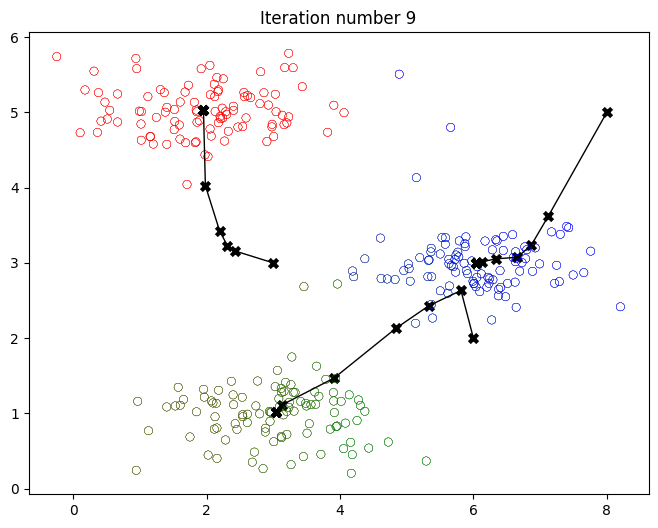


Final centroid positions:
[[1.95399466 5.02557006]
 [3.04367119 1.01541041]
 [6.03366736 3.00052511]]


In [143]:
# ============================================================
# Running K-Means on the Sample Dataset
# ============================================================

# Load the sample dataset for clustering.
X = load_data(PROJECT_DIR / "data" / "ex7_X.npy")

# Configure the initial centroid positions.
initial_centroids = np.array([
    [3, 3],
    [6, 2],
    [8, 5]
])

# Define the maximum number of clustering iterations.
max_iters = 10

# Execute K-Means and visualize the clustering progression.
centroids, idx = run_kMeans(
    X,
    initial_centroids,
    max_iters=max_iters,
    plot_progress=True
)

# Display the final clustering results.
print("\nFinal centroid positions:")
print(centroids)

**Random Centroid Initialization**

The initial positions of centroids can significantly influence the final clustering results produced by K-Means.

In the previous experiment, the initial centroids were manually specified to demonstrate how the algorithm assigns data points and updates cluster centers. However, manually selecting centroids is not always practical, particularly when working with larger or unfamiliar datasets.

A common initialization strategy is to randomly select K data points from the training dataset and use them as the initial centroids.

### Initialization Strategy

The random initialization process follows these steps:

1. **Shuffle dataset indices:** Use `np.random.permutation()` to generate a randomized ordering of the data point indices.
2. **Select K observations:** Choose the first K indices from the randomized sequence.
3. **Initialize centroids:** Use the corresponding data points as the initial centroid positions.

This approach ensures that the same data point is not selected more than once during initialization.

### Why Random Initialization Matters

Different initial centroid positions can lead to different clustering configurations. Random initialization allows K-Means to explore alternative starting positions without manually specifying the centroids.

For more reliable results, K-Means can be executed multiple times using different random initializations. The resulting clustering solutions can then be compared using the cost function (distortion).

In PixelForge, centroid initialization is particularly important because it influences how RGB colors are grouped into representative color clusters.

In [144]:
# ============================================================
# Random Centroid Initialization
# ============================================================

def kMeans_init_centroids(X, K):
    """
    Initialize K cluster centroids by randomly selecting
    distinct observations from the input dataset.

    Args:
        X (ndarray): Input dataset of shape (m, n).
        K (int): Number of clusters to initialize.

    Returns:
        centroids (ndarray): Initial centroid positions
                             of shape (K, n).
    """

    # Validate the requested number of clusters.
    if K <= 0 or K > X.shape[0]:
        raise ValueError("K must be between 1 and the number of data points.")

    # Randomly shuffle the dataset indices.
    random_indices = np.random.permutation(X.shape[0])

    # Select K distinct observations as initial centroids.
    centroids = X[random_indices[:K]].copy()

    return centroids

This cell demonstrates how random centroid initialization affects the final clustering results. Let's make it an experiment rather than an instruction to repeatedly run a course exercise.

K-Means iteration 1/10
K-Means iteration 2/10
K-Means iteration 3/10
K-Means iteration 4/10
K-Means iteration 5/10
K-Means iteration 6/10
K-Means iteration 7/10
K-Means iteration 8/10
K-Means iteration 9/10
K-Means iteration 10/10


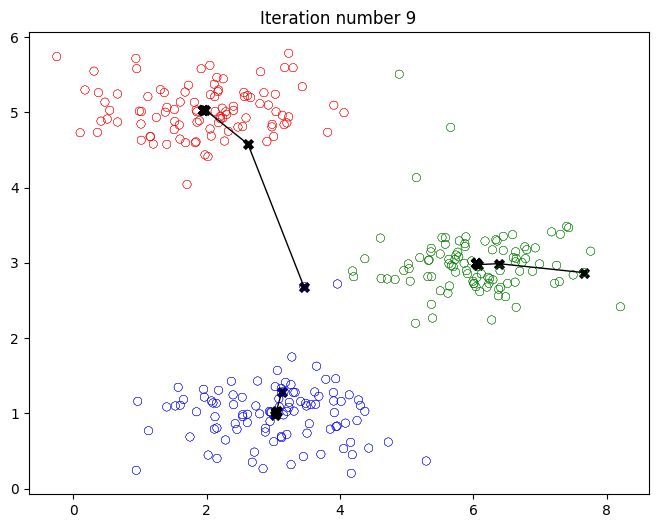


Final centroid positions:
[[1.95399466 5.02557006]
 [6.03366736 3.00052511]
 [3.04367119 1.01541041]]


In [145]:
# ============================================================
# Evaluating Random Centroid Initialization
# ============================================================

# Configure the clustering parameters.
K = 3
max_iters = 10

# Randomly select K observations as initial centroids.
initial_centroids = kMeans_init_centroids(X, K)

# Execute K-Means and visualize the clustering progression.
centroids, idx = run_kMeans(
    X,
    initial_centroids,
    max_iters=max_iters,
    plot_progress=True
)

# Display the final centroid positions.
print("\nFinal centroid positions:")
print(centroids)

**Image Color Quantization Using K-Means**

Having implemented and explored the K-Means algorithm, we can now apply it to image processing through **color quantization**.

Digital images commonly use the RGB color model, where each pixel is represented by three 8-bit unsigned integer values corresponding to:

- **Red (R):** Red channel intensity.
- **Green (G):** Green channel intensity.
- **Blue (B):** Blue channel intensity.

Each channel ranges from 0 to 255, allowing a standard 24-bit RGB image to represent approximately 16.7 million possible colors.

Images can contain thousands of distinct colors. PixelForge uses K-Means clustering to reduce this color space to a smaller representative palette while attempting to preserve the image's visual appearance.

### Color Quantization Approach

The process treats every pixel in the original image as an individual data point in a three-dimensional RGB feature space:

\[
x^{(i)} = [R^{(i)}, G^{(i)}, B^{(i)}]
\]

K-Means then groups pixels with similar RGB values into K clusters.

Each cluster centroid represents a representative color in the reduced palette. Once clustering is complete, every pixel is replaced with the RGB values of its assigned centroid.

For example, setting \(K=16\) produces a palette containing up to 16 representative colors.

### Palette-Based Representation

The resulting image contains no more than K distinct colors.

Conceptually, a palette-based representation can store:

1. The RGB values of the K representative colors.
2. A cluster index identifying the palette color assigned to each pixel.

For a palette of 16 colors, each pixel index can theoretically be represented using 4 bits, since:

\[
\log_2(16) = 4 \text{ bits}
\]

This illustrates how color quantization can support image compression by reducing the information needed to represent pixel colors.

Actual file-size reduction, however, depends on the encoding format, palette storage, and compression overhead.

### Project Objectives

This section applies the complete K-Means workflow to an RGB image:

1. Load and inspect the original image.
2. Transform the image pixels into RGB feature vectors.
3. Apply K-Means to identify representative colors.
4. Replace original pixel values with their assigned centroid colors.
5. Reconstruct and visualize the quantized image.

The resulting images will demonstrate the relationship between palette size, visual quality, and the potential for more compact image representation.

**Load image**

First, we will use `matplotlib` to read in the original image, as shown below

In [146]:
# Loading the original image
original_img = plt.imread(PROJECT_DIR / "bird_small.png")

Shape of original_img is: (128, 128, 3)


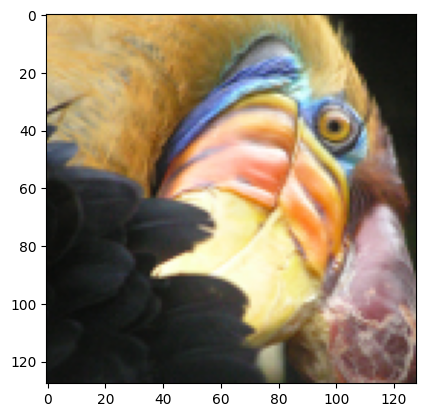

In [147]:
# Visualizing and checking the dimension of the image
plt.imshow(original_img)
print("Shape of original_img is:", original_img.shape)

**Image Dataset Preparation**

Before applying K-Means, the original image must be converted into a format compatible with the clustering algorithm.

An RGB image is represented as a three-dimensional NumPy array with the shape:

\[
(H, W, 3)
\]

Where:

- \(H\) represents the image height.
- \(W\) represents the image width.
- The third dimension contains the Red, Green, and Blue channel values.

Each pixel can be accessed using its row, column, and color channel indices. For example, `original_img[50, 33, 2]` retrieves the blue-channel intensity at row 50 and column 33.

**Preparing the data for K-Means**

The K-Means implementation expects a two-dimensional input matrix, with each row representing one observation.

The original image is reshaped into an $(m, 3)$ matrix, where $m = H \times W$. Each row represents one pixel, and its three columns contain the corresponding RGB values.

The resulting matrix can then be passed directly to the K-Means algorithm.

**Pixel value scaling**

Pixel values must use a consistent numerical range. Depending on the image format and loading method, values may be represented in the range [0, 255] or [0, 1].

We will inspect the loaded image's values before processing to ensure the data is represented correctly.

In [148]:
# ============================================================
# Image Dataset Preparation
# ============================================================

# Normalize pixel values when the image is stored in the 0–255 range.
# Images already represented in the 0–1 range do not require scaling.
if original_img.max() > 1.0:
    original_img = original_img.astype(np.float32) / 255.0

# Retrieve the image dimensions.
H, W, C = original_img.shape

# Reshape the image into a two-dimensional RGB pixel dataset.
# Each row represents one pixel, with its Red, Green, and Blue values.
X_img = original_img.reshape(H * W, C)

# Verify the prepared dataset.
print("Original image dimensions:", (H, W, C))
print("Prepared pixel dataset shape:", X_img.shape)
print("Pixel value range:", X_img.min(), "to", X_img.max())

Original image dimensions: (128, 128, 3)
Prepared pixel dataset shape: (16384, 3)
Pixel value range: 0.023529412 to 1.0


Now Lets run the cell below to run K-means on the pre-processed image.

In [149]:
# ============================================================
# Applying K-Means to RGB Pixels
# ============================================================

# Configure the color quantization parameters.
K = 16
max_iters = 10

# Initialize K centroids by randomly selecting RGB pixel values.
initial_centroids = kMeans_init_centroids(X_img, K)

# Cluster the RGB pixels using K-Means.
centroids, idx = run_kMeans(
    X_img,
    initial_centroids,
    max_iters=max_iters
)

print(f"\nK-Means clustering completed.")
print(f"Number of color clusters: {K}")
print(f"Number of iterations: {max_iters}")
print("Final centroid shape:", centroids.shape)
print("Cluster assignment shape:", idx.shape)

K-Means iteration 1/10
K-Means iteration 2/10
K-Means iteration 3/10
K-Means iteration 4/10
K-Means iteration 5/10
K-Means iteration 6/10
K-Means iteration 7/10
K-Means iteration 8/10
K-Means iteration 9/10
K-Means iteration 10/10

K-Means clustering completed.
Number of color clusters: 16
Number of iterations: 10
Final centroid shape: (16, 3)
Cluster assignment shape: (16384,)


This visualization displays the RGB color distribution of the original image in three-dimensional color space. Each point represents a pixel, while the centroid markers identify the 16 representative colors learned by K-Means.

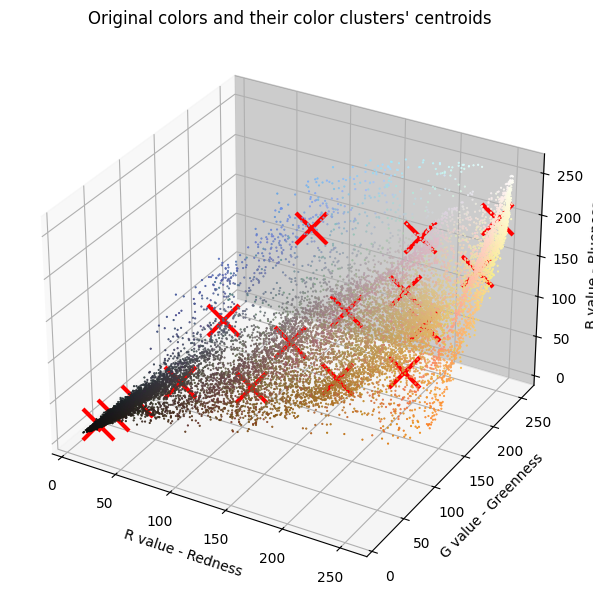

In [150]:
# ============================================================
# Visualizing RGB Clusters and Representative Colors
# ============================================================

# Visualize the original RGB pixel distribution and the learned centroids.
plot_kMeans_RGB(X_img, centroids, idx, K)

Lets visualize the colors at each of the red markers (i.e. the centroids) above with the function below. You will only see these colors when you generate the new image in the next section. The number below each color is its index and these are the numbers you see in the `idx` array.&#x20;


\# Visualize the 16 colors selected\
show_centroid_colors(centroids)

Edit this markdown and code cell

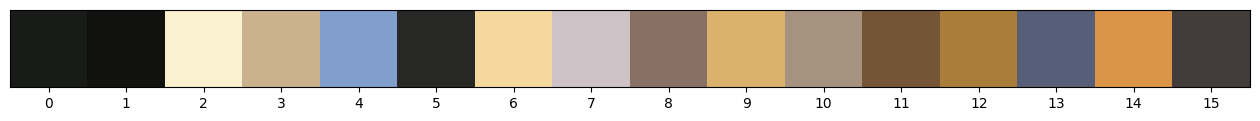

In [151]:
# ============================================================
# 6.3 Visualizing the Representative Color Palette
# ============================================================

# Display the RGB colors represented by the learned centroids.
show_centroid_colors(centroids)

**Reconstructing the Image Using Cluster Assignments**

With the 16 representative colors identified, each pixel can now be mapped to its nearest centroid.

The resulting cluster assignments provide a compact representation of the image:

- Each pixel is represented by the index of its assigned centroid rather than its original RGB values.
- The 16 centroids form a color palette, requiring 24 bits per color (8 bits per RGB channel).
- Since 16 unique colors require only 4 bits to identify each color, each pixel can theoretically be represented using 4 bits instead of the original 24 bits.

Theoretical storage comparison

For a \\(128 \times 128\\) image:

| Representation                 | Storage                                       |
| ------------------------------ | --------------------------------------------- |
| Original RGB image             | \\(128 \times 128 \times 24 = 393,216\\) bits |
| 16-color palette               | \\(16 \times 24 = 384\\) bits                 |
| Pixel indices                  | \\(128 \times 128 \times 4 = 65,536\\) bits   |
| Total quantized representation | 65,920 bits                                   |

This represents a theoretical reduction in storage of approximately 6 times compared with the original 24-bit RGB representation.

Note: This comparison assumes ideal palette-based storage. Actual file sizes depend on the image encoding format, metadata, and compression overhead. K-Means reduces the number of colors; the storage benefit depends on how the quantized image is encoded.

In [152]:
# ============================================================
# Image Reconstruction
# ============================================================

# Assign each RGB pixel to its nearest learned centroid.
idx = find_closest_centroids(X_img, centroids)

# Replace each pixel with the RGB values of its assigned centroid.
X_recovered = centroids[idx]

# Restore the original image dimensions.
X_recovered = X_recovered.reshape(original_img.shape)

# Verify the reconstructed image dimensions.
print("Reconstructed image shape:", X_recovered.shape)
print("Reconstructed pixel value range:",
      X_recovered.min(), "to", X_recovered.max())

Reconstructed image shape: (128, 128, 3)
Reconstructed pixel value range: 0.06370894293942861 to 0.9790791639955598


**Comparing the Original and Quantized Images**

The reconstructed image uses the representative colors learned by K-Means instead of the original pixel colors.

By comparing the two images, we can evaluate the visual impact of reducing the color palette to 16 colors.

Although the reconstructed image retains the overall structure and recognizable features of the original, some visual details may be lost. These differences appear as quantization artifacts, particularly in areas with subtle color variations.

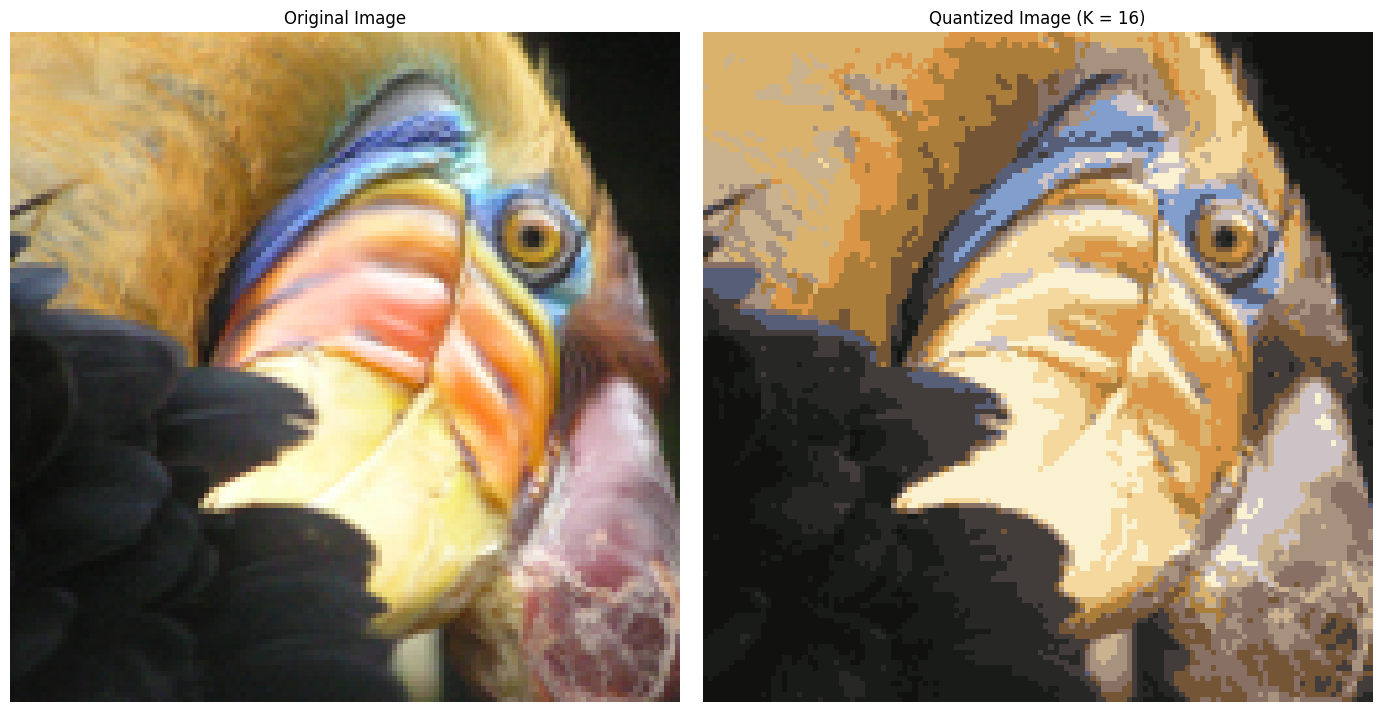

In [153]:
# ============================================================
# 6.5 Original vs. Quantized Image
# ============================================================

# Create a side-by-side comparison of the original and reconstructed images.
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

# Display the original RGB image.
ax[0].imshow(original_img)
ax[0].set_title("Original Image")
ax[0].axis("off")

# Display the image reconstructed using the K-Means color palette.
ax[1].imshow(X_recovered)
ax[1].set_title(f"Quantized Image (K = {K})")
ax[1].axis("off")

plt.tight_layout()
plt.show()

## Project Conclusion

PixelForge demonstrates how K-Means clustering can be applied to image color quantization. By grouping similar RGB pixel values into clusters, we reduced the image's color palette to 16 representative colors while preserving its overall visual structure.

This project highlights the practical application of unsupervised learning in image processing and demonstrates the trade-off between color representation, visual fidelity, and potential storage efficiency.

**Key takeaway:** K-Means is not limited to traditional data clustering; it can also be used to solve practical problems in computer vision and image optimization.